<a href="https://colab.research.google.com/github/10ans47h/statistical-foundation-of-data-science/blob/main/Final%20Report/final_practical_stats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Loaded Successfully!")
print("Total Samples:", X.shape[0])
print("Total Features:", X.shape[1])

Dataset Loaded Successfully!
Total Samples: 569
Total Features: 30


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 398
Testing Samples: 171


In [5]:
pca_raw = PCA()

pca_raw.fit(X_train)

raw_variance = pca_raw.explained_variance_ratio_[0]

print("PC1 Explained Variance (Raw Data):",
      round(raw_variance * 100, 2), "%")


dominant_index = np.argmax(np.abs(pca_raw.components_[0]))

print("Dominant Feature:",
      data.feature_names[dominant_index])

PC1 Explained Variance (Raw Data): 98.54 %
Dominant Feature: worst area


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)


pca_scaled = PCA()

pca_scaled.fit(X_train_scaled)

scaled_variance = pca_scaled.explained_variance_ratio_[0]

print("PC1 Explained Variance (Standardised Data):",
      round(scaled_variance * 100, 2), "%")

PC1 Explained Variance (Standardised Data): 45.16 %


In [7]:
k_values = [2, 5, 10, 30]

results = []

for k in k_values:

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=k)),
        ('classifier', LogisticRegression(max_iter=1000))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'PCA Components': k,
        'Test Accuracy (%)': round(accuracy * 100, 2)
    })

    print("Components:", k,
          "| Accuracy:", round(accuracy * 100, 2), "%")

Components: 2 | Accuracy: 94.74 %
Components: 5 | Accuracy: 97.66 %
Components: 10 | Accuracy: 97.08 %
Components: 30 | Accuracy: 98.83 %


In [8]:
results_df = pd.DataFrame(results)

print("ACCURACY COMPARISON TABLE")

display(results_df)

ACCURACY COMPARISON TABLE


,PCA Components,Test Accuracy (%)
0,2,94.74
1,5,97.66
2,10,97.08
3,30,98.83


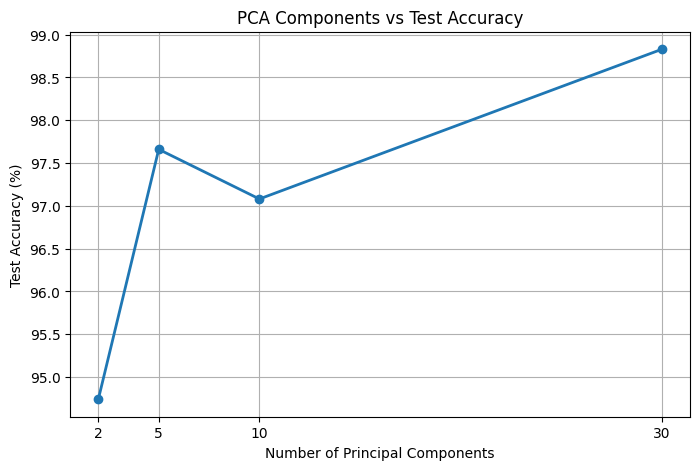

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df['PCA Components'],
    results_df['Test Accuracy (%)'],
    marker='o',
    linewidth=2
)

plt.title("PCA Components vs Test Accuracy")

plt.xlabel("Number of Principal Components")

plt.ylabel("Test Accuracy (%)")

plt.xticks(k_values)

plt.grid(True)

plt.show()

In [10]:
accuracy_30 = results_df.loc[
    results_df['PCA Components'] == 30,
    'Test Accuracy (%)'
].iloc[0]

eligible = results_df[
    (accuracy_30 - results_df['Test Accuracy (%)']) <= 1
]

smallest_k = eligible['PCA Components'].min()

print("Accuracy of 30-component model:", accuracy_30, "%")

print("Smallest k within 1 percentage point:", smallest_k)

Accuracy of 30-component model: 98.83 %
Smallest k within 1 percentage point: 30
